# Milestone 2 - Classical Forecasting of Delhi PM2.5
Time Series & Analysis Project - Milestone 2 (Mid-Sem): classical forecasting models  
Delhi air quality: PM2.5 (target), PM10, NO2, CO, CO2, AQI  |  daily, 2022-08-01 .. 2026-10-20  
Run:  python milestone2_analysis.py   (re-creates every figure and table in ../figures and ../results)

In [1]:
import os, warnings, json
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd(); ROOT = os.path.dirname(HERE)
DATA, FIG, RES = (os.path.join(ROOT, d) for d in ("data", "figures", "results"))
TEAL, ORANGE, GREY, RED = "#1F8A7D", "#C4801A", "#5B7075", "#D1503F"
plt.rcParams.update({"figure.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
TEST_DAYS, H = 90, 7                      # hold-out length, multi-step horizon

## 1. load & preprocess

In [2]:
raw = pd.read_csv(os.path.join(DATA, "delhi_hourly_raw.csv"), parse_dates=["time"]).set_index("time")
cols = {"pm2_5": "PM2.5", "pm10": "PM10", "nitrogen_dioxide": "NO2", "carbon_monoxide": "CO",
        "carbon_dioxide": "CO2", "us_aqi": "AQI"}
raw = raw.rename(columns=cols)
daily = raw.resample("D").mean()
n_missing = daily.isna().sum(); longest = {}
for c in daily:
    m = daily[c].isna().astype(int); g = (m.diff() != 0).cumsum(); longest[c] = int(m.groupby(g).sum().max())
daily = daily.interpolate(limit=3).bfill(limit=4).round(3)
daily.index.name = "date"; daily.to_csv(os.path.join(DATA, "delhi_daily_air_quality.csv"))
y = daily["PM2.5"]; ly = np.log(y.clip(lower=1.0))  # floor at 1 ug/m3 before log
prep = dict(rows=len(daily), start=str(daily.index.min().date()), end=str(daily.index.max().date()),
            missing_after_resample=n_missing.to_dict(), longest_gap_days=longest)
print(prep)

{'rows': 1542, 'start': '2022-08-01', 'end': '2026-10-20', 'missing_after_resample': {'PM2.5': 3, 'PM10': 3, 'NO2': 3, 'CO': 3, 'CO2': 817, 'AQI': 4}, 'longest_gap_days': {'PM2.5': 3, 'PM10': 3, 'NO2': 3, 'CO': 3, 'CO2': 817, 'AQI': 4}}


## 2. EDA figures

In [3]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for a, c, col in zip(ax, ["PM2.5", "PM10", "NO2"], [TEAL, ORANGE, GREY]):
    a.plot(daily[c], color=col, lw=.8); a.set_ylabel(f"{c} (µg/m³)")
fig.suptitle("Delhi daily PM2.5, PM10 and NO2 (Aug 2022 - Oct 2026)", weight="bold"); fig.tight_layout()
fig.savefig(os.path.join(FIG, "01_daily_pollutants.png")); plt.close(fig)

stl = STL(y, period=365, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(10, 7); fig.suptitle("STL decomposition of daily PM2.5 (period = 365)", weight="bold")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "02_stl_decomposition.png")); plt.close(fig)
seas_strength = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())

mon = daily.groupby(daily.index.month).mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for yr, g in y.groupby(y.index.year):
    s = g.groupby(g.index.month).mean(); ax[0].plot(s.index, s.values, marker="o", ms=3, label=str(yr))
ax[0].set_title("Monthly mean PM2.5 by year"); ax[0].set_xlabel("Month"); ax[0].legend(fontsize=8)
nm = (daily[["PM2.5", "PM10", "NO2", "CO"]] / daily[["PM2.5", "PM10", "NO2", "CO"]].max()).corr()
im = ax[1].imshow(daily[["PM2.5", "PM10", "NO2", "CO", "CO2"]].corr(), cmap="RdBu_r", vmin=-1, vmax=1)
lab = ["PM2.5", "PM10", "NO2", "CO", "CO2"]; ax[1].set_xticks(range(5), lab); ax[1].set_yticks(range(5), lab); ax[1].grid(False)
cm = daily[lab].corr()
for i in range(5):
    for j in range(5): ax[1].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(cm.iloc[i, j]) > .6 else "black")
ax[1].set_title("Correlation matrix"); fig.tight_layout(); fig.savefig(os.path.join(FIG, "03_seasonal_and_correlation.png")); plt.close(fig)
cm.round(3).to_csv(os.path.join(RES, "correlation_matrix.csv"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(y, bins=40, color=TEAL); ax[0].set_title("PM2.5 distribution (skewed)")
ax[1].hist(ly, bins=40, color=ORANGE); ax[1].set_title("log(PM2.5) distribution (near-symmetric)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "04_histograms.png")); plt.close(fig)

co2 = daily["CO2"].dropna()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(co2, color=GREY, lw=.8); ax[0].set_title(f"CO2 (ppm), {co2.index.min().date()} onward ({len(co2)} days)"); ax[0].set_ylabel("ppm")
ov = daily.loc[co2.index]; ax[1].scatter(ov["CO2"], ov["PM2.5"], s=5, color=TEAL, alpha=.5); ax[1].set_xlabel("CO2 (ppm)"); ax[1].set_ylabel("PM2.5 (µg/m³)")
ax[1].set_title(f"CO2 vs PM2.5 (r = {ov['CO2'].corr(ov['PM2.5']):.2f})"); fig.tight_layout(); fig.savefig(os.path.join(FIG, "10_co2_vs_pm25.png")); plt.close(fig)

## 3. stationarity

In [4]:
def tests(s, name):
    a = adfuller(s.dropna(), autolag="AIC"); k = kpss(s.dropna(), regression="c", nlags="auto")
    return dict(series=name, ADF_stat=round(a[0], 3), ADF_p=round(a[1], 4), KPSS_stat=round(k[0], 3), KPSS_p=round(k[1], 4),
                verdict=("stationary" if a[1] < .05 and k[1] >= .05 else "conflicting" if (a[1] < .05) != (k[1] >= .05) else "non-stationary"))
st = pd.DataFrame([tests(y, "PM2.5"), tests(ly, "log PM2.5"), tests(ly.diff(), "diff(log PM2.5)"),
                   tests(ly.diff(7), "log PM2.5, seasonal diff (7)"), tests(daily["NO2"], "NO2"), tests(daily["PM10"], "PM10")])
st.to_csv(os.path.join(RES, "stationarity_tests.csv"), index=False); print(st.to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
plot_acf(ly.dropna(), lags=60, ax=ax[0], color=TEAL); plot_pacf(ly.dropna(), lags=60, ax=ax[1], color=ORANGE, method="ywm")
ax[0].set_title("ACF of log PM2.5"); ax[1].set_title("PACF of log PM2.5"); fig.tight_layout()
fig.savefig(os.path.join(FIG, "05_acf_pacf.png")); plt.close(fig)

                         series  ADF_stat   ADF_p  KPSS_stat  KPSS_p      verdict
0                         PM2.5    -4.896  0.0000      0.334  0.1000   stationary
1                     log PM2.5    -5.374  0.0000      0.486  0.0447  conflicting
2               diff(log PM2.5)   -12.982  0.0000      0.040  0.1000   stationary
3  log PM2.5, seasonal diff (7)   -10.358  0.0000      0.010  0.1000   stationary
4                           NO2    -2.942  0.0407      2.557  0.0100  conflicting
5                          PM10    -3.343  0.0130      1.457  0.0100  conflicting


## 4. split + helpers

In [5]:
train, test = ly.iloc[:-TEST_DAYS], ly.iloc[-TEST_DAYS:]
def fourier(idx, K=2):
    t = np.asarray((idx - pd.Timestamp("2022-01-01")).days, float)
    return pd.DataFrame({f"{f}{k}": getattr(np, f)(2 * np.pi * k * t / 365.25) for k in range(1, K + 1) for f in ("sin", "cos")}, index=idx)
X = fourier(ly.index)
def metrics(actual_log, pred_log):
    a, p = np.exp(actual_log), np.exp(pred_log); e = a - p
    return dict(RMSE=float(np.sqrt((e ** 2).mean())), MAE=float(e.abs().mean()), MAPE=float((e.abs() / a).mean() * 100))

# model catalogue: each returns (fitted result on train, label, description)
specs = {}
def fit_arima(order):  return SARIMAX(train, order=order, trend="c").fit(disp=False)
def fit_sarima(order, seas): return SARIMAX(train, exog=X.loc[train.index], order=order, seasonal_order=seas).fit(disp=False, maxiter=200)
def hw(series): return ExponentialSmoothing(series, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7, initialization_method="estimated")
def fit_ets(): return hw(train).fit()
def hw_apply(r, hist):
    pr = r.params; return hw(hist).fit(smoothing_level=pr["smoothing_level"], smoothing_trend=pr["smoothing_trend"], smoothing_seasonal=pr["smoothing_seasonal"], damping_trend=pr["damping_trend"], optimized=False)

# ARIMA order search on training data by AIC (d=0/1 justified by tests)
rows = []
for p in range(4):
    for d in (0, 1):
        for q in range(4):
            if p == q == 0: continue
            try: r = SARIMAX(train, order=(p, d, q), trend="c" if d == 0 else "n").fit(disp=False); rows.append((p, d, q, r.aic, r.bic))
            except Exception: pass
grid = pd.DataFrame(rows, columns=["p", "d", "q", "AIC", "BIC"]).sort_values("AIC").reset_index(drop=True)
grid.head(10).round(2).to_csv(os.path.join(RES, "arima_order_search_top10.csv"), index=False)
p, d, q = (int(v) for v in grid.loc[0, ["p", "d", "q"]]); print("ARIMA order:", (p, d, q))
SARIMA_ORDER = (p, d, q)

models = {}
models["ARIMA"] = (SARIMAX(train, order=(p, d, q), trend="c" if d == 0 else "n").fit(disp=False), None)
models["SARIMA (7) + yearly Fourier"] = (SARIMAX(train, exog=X.loc[train.index], order=(p, d, q), seasonal_order=(1, 0, 1, 7)).fit(disp=False, maxiter=300), X)
models["Holt-Winters (damped, m=7)"] = (fit_ets(), None)
for k, (r, _) in models.items(): print(k, "AIC", round(float(r.aic), 1))

def one_step(name):
    r, ex = models[name]
    if name.startswith("Holt"):
        pr = hw_apply(r, ly).fittedvalues
    else:
        ap = r.apply(ly, exog=None if ex is None else ex.loc[ly.index], refit=False); pr = ap.fitted_values if hasattr(ap, "fitted_values") else ap.fittedvalues
    return pr.loc[test.index]

def multi_step(name, h=H):
    out = pd.Series(index=test.index, dtype=float); r, ex = models[name]
    for i in range(0, TEST_DAYS, h):
        origin = test.index[i]; hist = ly.loc[:origin - pd.Timedelta(days=1)]; idx = test.index[i:i + h]
        if name.startswith("Holt"): f = hw_apply(r, hist).forecast(len(idx))
        else:
            ap = r.apply(hist, exog=None if ex is None else ex.loc[hist.index], refit=False)
            f = ap.forecast(len(idx), exog=None if ex is None else ex.loc[idx])
        out.loc[idx] = np.asarray(f)
    return out

# baselines
base1 = {"Naive (yesterday)": ly.shift(1).loc[test.index], "Seasonal naive (7 d)": ly.shift(7).loc[test.index]}
def base_h(lag):
    o = pd.Series(index=test.index, dtype=float)
    for i in range(0, TEST_DAYS, H):
        idx = test.index[i:i + H]; o.loc[idx] = ly.loc[test.index[i] - pd.Timedelta(days=1)] if lag == 1 else [ly.loc[t - pd.Timedelta(days=7 * (1 + (t - test.index[i]).days // 7))] for t in idx]
    return o
baseH = {"Naive (yesterday)": base_h(1), "Seasonal naive (7 d)": base_h(7)}

p1, pH = dict(base1), dict(baseH)
for n in models: p1[n] = one_step(n); pH[n] = multi_step(n)
tab = []
for n in p1:
    a, b = metrics(test, p1[n]), metrics(test, pH[n])
    tab.append(dict(Model=n, **{f"h=1 {k}": round(v, 2) for k, v in a.items()}, **{f"h={H} {k}": round(v, 2) for k, v in b.items()}))
tab = pd.DataFrame(tab).sort_values("h=1 RMSE").reset_index(drop=True)
tab.to_csv(os.path.join(RES, "model_comparison.csv"), index=False); print(tab.to_string())

# diagnostics
lb = {}
for n, (r, _) in models.items():
    res = pd.Series(np.asarray(r.resid), index=train.index).iloc[10:]
    l = acorr_ljungbox(res, lags=[10, 20], return_df=True); lb[n] = dict(LB_p_lag10=round(float(l.lb_pvalue.iloc[0]), 4), LB_p_lag20=round(float(l.lb_pvalue.iloc[1]), 4), AIC=(None if n.startswith("Holt") else round(float(r.aic), 1)), BIC=(None if n.startswith("Holt") else round(float(r.bic), 1)))
pd.DataFrame(lb).T.to_csv(os.path.join(RES, "residual_diagnostics.csv")); print(pd.DataFrame(lb).T)

# plots
best = tab.loc[tab.Model.isin(models), "Model"].iloc[0]
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(np.exp(ly.iloc[-150:]), color="black", lw=1.2, label="Actual")
for n, c in zip(models, [GREY, TEAL, ORANGE]): ax[0].plot(np.exp(p1[n]), color=c, lw=1.1, label=n)
ax[0].set_title("Next-day (h = 1) forecasts on the 90-day hold-out", weight="bold"); ax[0].set_ylabel("PM2.5 (µg/m³)"); ax[0].legend(fontsize=8, ncol=2)
ax[1].plot(np.exp(ly.iloc[-150:]), color="black", lw=1.2, label="Actual")
for n, c in zip(models, [GREY, TEAL, ORANGE]): ax[1].plot(np.exp(pH[n]), color=c, lw=1.1, label=n)
ax[1].set_title(f"{H}-day-ahead forecasts re-issued every {H} days", weight="bold"); ax[1].set_ylabel("PM2.5 (µg/m³)"); ax[1].legend(fontsize=8, ncol=2)
for a in ax: a.axvline(test.index[0], color=RED, ls="--", lw=1)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "06_forecasts.png")); plt.close(fig)

r, ex = models[best]
res = pd.Series(np.asarray(r.resid), index=train.index).iloc[10:]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
ax[0].plot(res, color=TEAL, lw=.6); ax[0].set_title(f"Residuals: {best}")
plot_acf(res, lags=40, ax=ax[1], color=TEAL); ax[1].set_title("Residual ACF")
ax[2].hist(res, bins=40, color=ORANGE); ax[2].set_title("Residual histogram")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "07_residual_diagnostics.png")); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 3.6)); w = .38; xs = np.arange(len(tab))
ax.bar(xs - w / 2, tab["h=1 RMSE"], w, color=TEAL, label="h = 1"); ax.bar(xs + w / 2, tab[f"h={H} RMSE"], w, color=ORANGE, label=f"h = {H}")
ax.set_xticks(xs, [m.replace(" + ", "\n+ ").replace(" (", "\n(") for m in tab.Model], fontsize=8); ax.set_ylabel("RMSE (µg/m³)"); ax.legend(); ax.set_title("Hold-out RMSE by model", weight="bold")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "08_rmse_comparison.png")); plt.close(fig)

# 30-day genuine out-of-sample forecast beyond the last observation (best model)
fut = pd.date_range(ly.index[-1] + pd.Timedelta(days=1), periods=14)
rf = SARIMAX(ly, exog=X, order=SARIMA_ORDER, seasonal_order=(1, 0, 1, 7)).fit(disp=False, maxiter=300)
fc = rf.get_forecast(14, exog=fourier(fut)); ci = fc.conf_int(alpha=.2)
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.plot(np.exp(ly.iloc[-60:]), color="black", label="Observed")
ax.plot(fut, np.exp(fc.predicted_mean), color=TEAL, label="SARIMA forecast"); ax.fill_between(fut, np.exp(ci.iloc[:, 0]), np.exp(ci.iloc[:, 1]), color=TEAL, alpha=.2, label="80% interval")
ax.set_title(f"14-day PM2.5 outlook after {ly.index[-1].date()}", weight="bold"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(FIG, "09_future_outlook.png")); plt.close(fig)
pd.DataFrame({"date": fut, "forecast": np.exp(fc.predicted_mean).round(1).values, "lo80": np.exp(ci.iloc[:, 0]).round(1).values, "hi80": np.exp(ci.iloc[:, 1]).round(1).values}).to_csv(os.path.join(RES, "future_14day_forecast.csv"), index=False)

summary = dict(prep=prep, best_model=best, arima_order=SARIMA_ORDER, stl_seasonal_strength=round(float(seas_strength), 3),
               pm25=dict(mean=round(float(y.mean()), 1), median=round(float(y.median()), 1), max=round(float(y.max()), 1), max_date=str(y.idxmax().date()), min=round(float(y.min()), 1)),
               monthly_mean_pm25=mon["PM2.5"].round(1).to_dict(), yearly_mean=y.groupby(y.index.year).mean().round(1).to_dict(),
               co2=dict(first=round(float(daily["CO2"].iloc[:30].mean()), 1), last=round(float(daily["CO2"].iloc[-30:].mean()), 1)),
               test_window=[str(test.index[0].date()), str(test.index[-1].date())], days_above_60=int((y > 60).sum()), pct_above_60=round(float((y > 60).mean() * 100), 1),
               outliers_iqr=int(((y < y.quantile(.25) - 1.5 * (y.quantile(.75) - y.quantile(.25))) | (y > y.quantile(.75) + 1.5 * (y.quantile(.75) - y.quantile(.25)))).sum()),
               outliers_z3=int((((y - y.mean()) / y.std()).abs() > 3).sum()))
json.dump(summary, open(os.path.join(RES, "summary.json"), "w"), indent=1, default=str); print(json.dumps(summary, indent=1, default=str))

ARIMA order: (3, 0, 3)


ARIMA AIC 389.6
SARIMA (7) + yearly Fourier AIC 391.1
Holt-Winters (damped, m=7) AIC -3478.1


                         Model  h=1 RMSE  h=1 MAE  h=1 MAPE  h=7 RMSE  h=7 MAE  h=7 MAPE
0                        ARIMA     14.95    12.05     23.05     19.96    16.41     33.24
1  SARIMA (7) + yearly Fourier     15.14    12.11     22.99     20.13    16.28     32.74
2            Naive (yesterday)     15.76    12.66     23.64     19.28    14.88     31.50
3   Holt-Winters (damped, m=7)     17.52    14.13     26.05     23.84    18.81     41.07
4         Seasonal naive (7 d)     37.58    26.38     54.77     37.58    26.38     54.77
                             LB_p_lag10  LB_p_lag20    AIC    BIC
ARIMA                            0.9621      0.8376  389.6  431.9
SARIMA (7) + yearly Fourier      0.8494      0.4746  391.1  459.8
Holt-Winters (damped, m=7)       0.0000      0.0000    NaN    NaN


{
 "prep": {
  "rows": 1542,
  "start": "2022-08-01",
  "end": "2026-10-20",
  "missing_after_resample": {
   "PM2.5": 3,
   "PM10": 3,
   "NO2": 3,
   "CO": 3,
   "CO2": 817,
   "AQI": 4
  },
  "longest_gap_days": {
   "PM2.5": 3,
   "PM10": 3,
   "NO2": 3,
   "CO": 3,
   "CO2": 817,
   "AQI": 4
  }
 },
 "best_model": "ARIMA",
 "arima_order": [
  3,
  0,
  3
 ],
 "stl_seasonal_strength": 0.633,
 "pm25": {
  "mean": 74.1,
  "median": 65.2,
  "max": 256.7,
  "max_date": "2025-01-10",
  "min": 0.6
 },
 "monthly_mean_pm25": {
  "1": 121.3,
  "2": 72.6,
  "3": 67.8,
  "4": 57.6,
  "5": 73.8,
  "6": 69.7,
  "7": 54.2,
  "8": 51.3,
  "9": 49.3,
  "10": 72.0,
  "11": 104.5,
  "12": 106.7
 },
 "yearly_mean": {
  "2022": 81.6,
  "2023": 66.2,
  "2024": 65.9,
  "2025": 80.3,
  "2026": 82.5
 },
 "co2": {
  "first": NaN,
  "last": 469.1
 },
 "test_window": [
  "2026-07-23",
  "2026-10-20"
 ],
 "days_above_60": 869,
 "pct_above_60": 56.4,
 "outliers_iqr": 39,
 "outliers_z3": 18
}


## Result gallery (saved figures and metric tables)

                         Model  h=1 RMSE  h=1 MAE  h=1 MAPE  h=7 RMSE  h=7 MAE  h=7 MAPE
0                        ARIMA     14.95    12.05     23.05     19.96    16.41     33.24
1  SARIMA (7) + yearly Fourier     15.14    12.11     22.99     20.13    16.28     32.74
2            Naive (yesterday)     15.76    12.66     23.64     19.28    14.88     31.50
3   Holt-Winters (damped, m=7)     17.52    14.13     26.05     23.84    18.81     41.07
4         Seasonal naive (7 d)     37.58    26.38     54.77     37.58    26.38     54.77


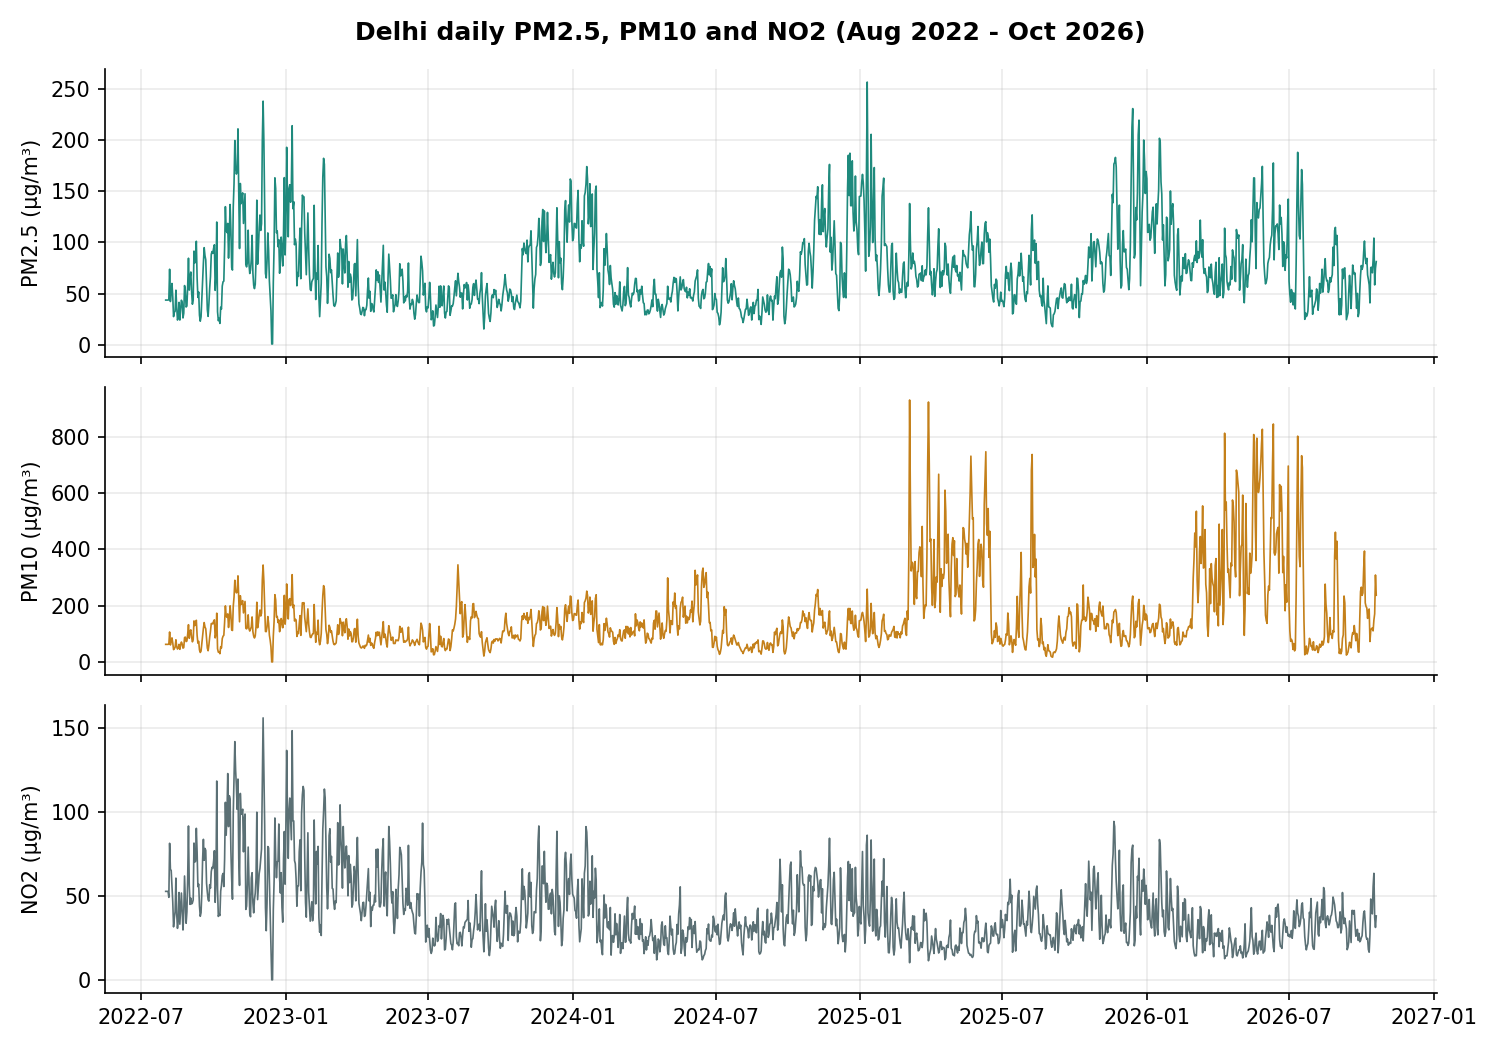

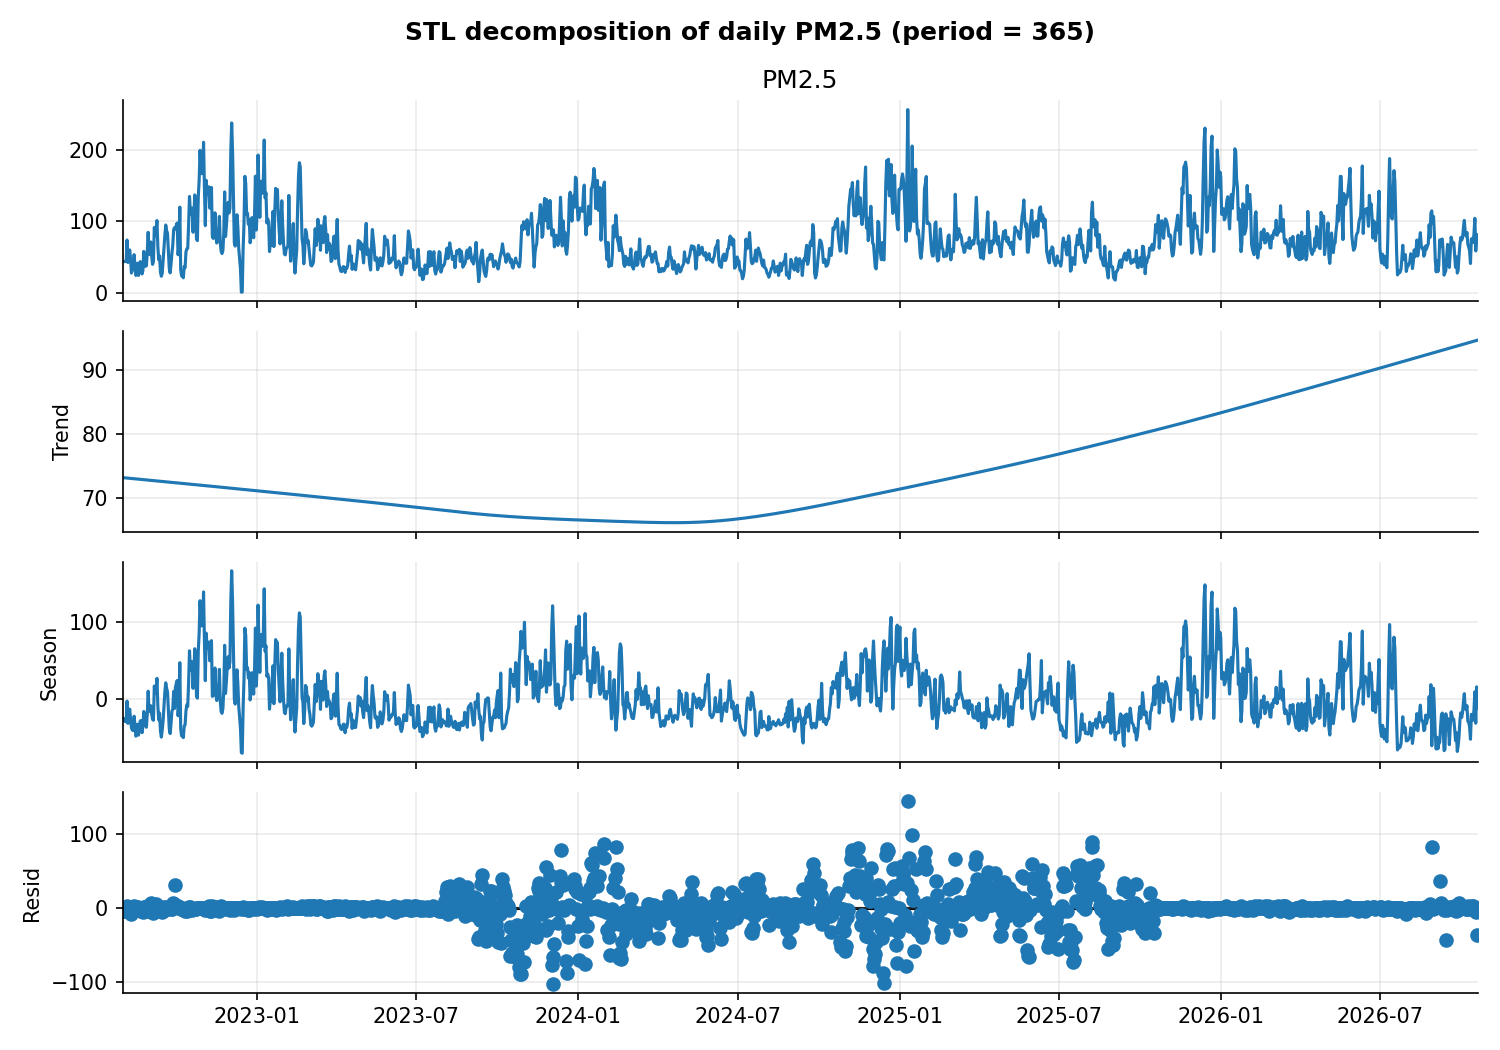

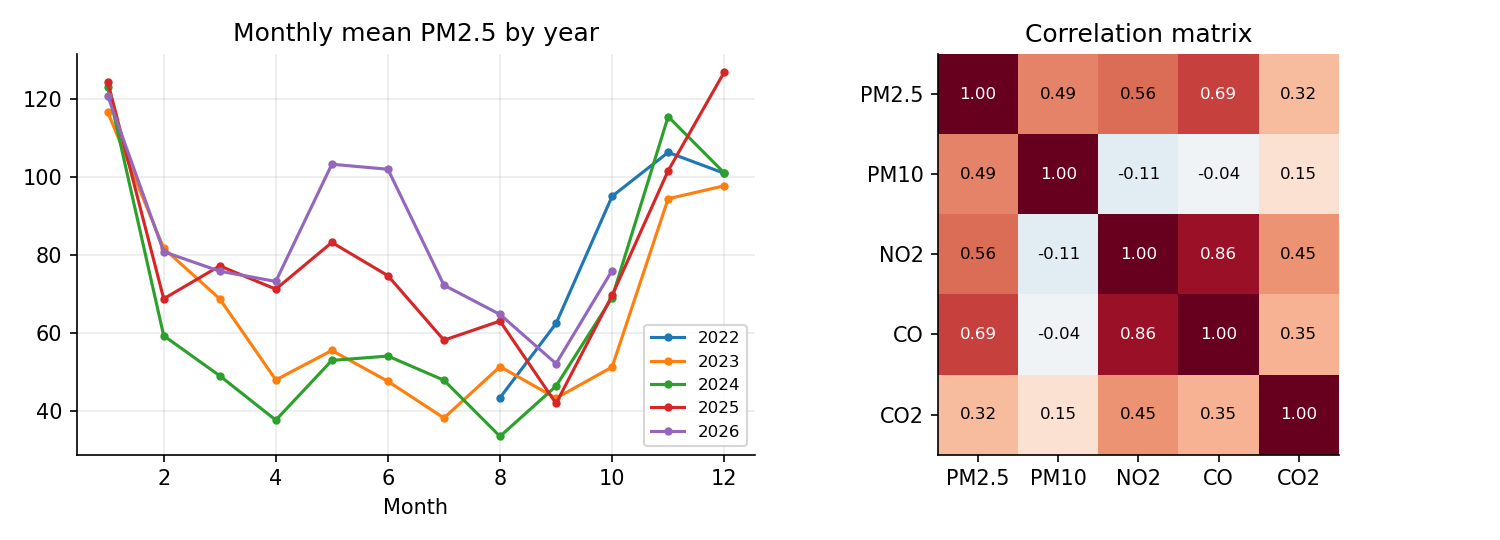

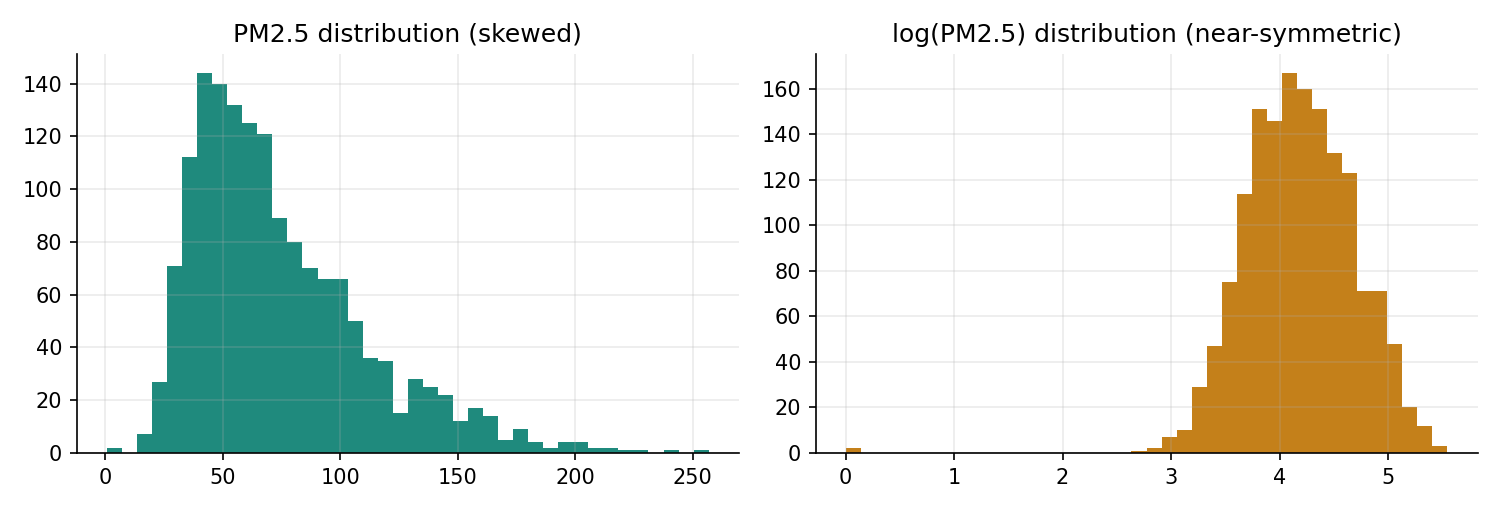

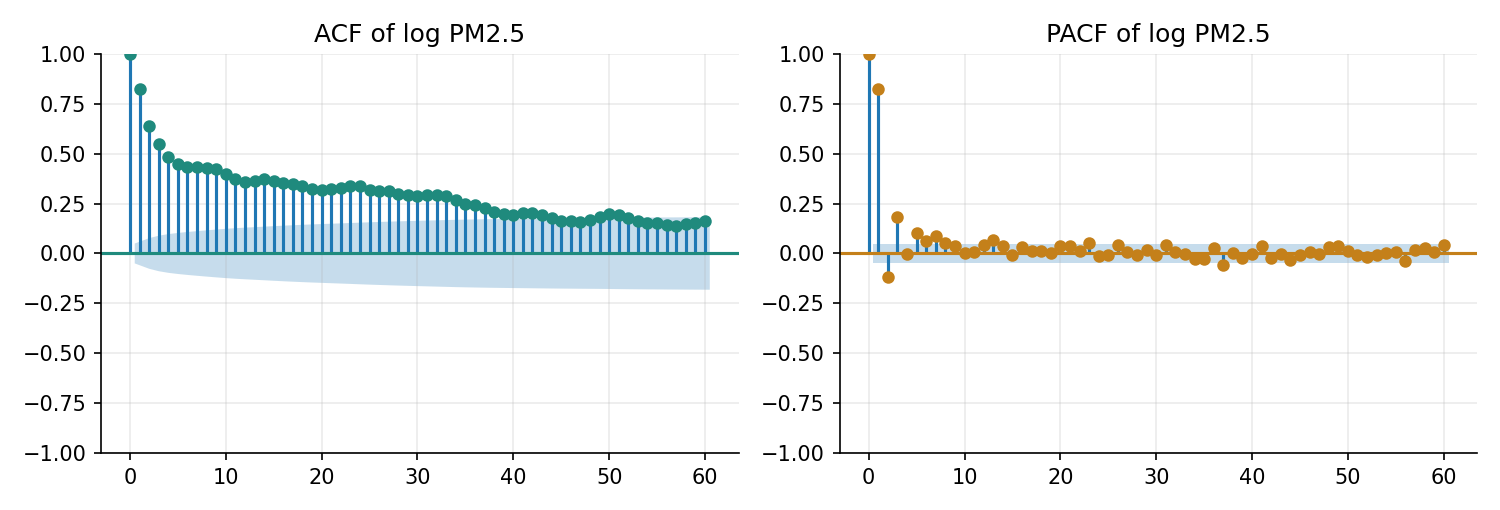

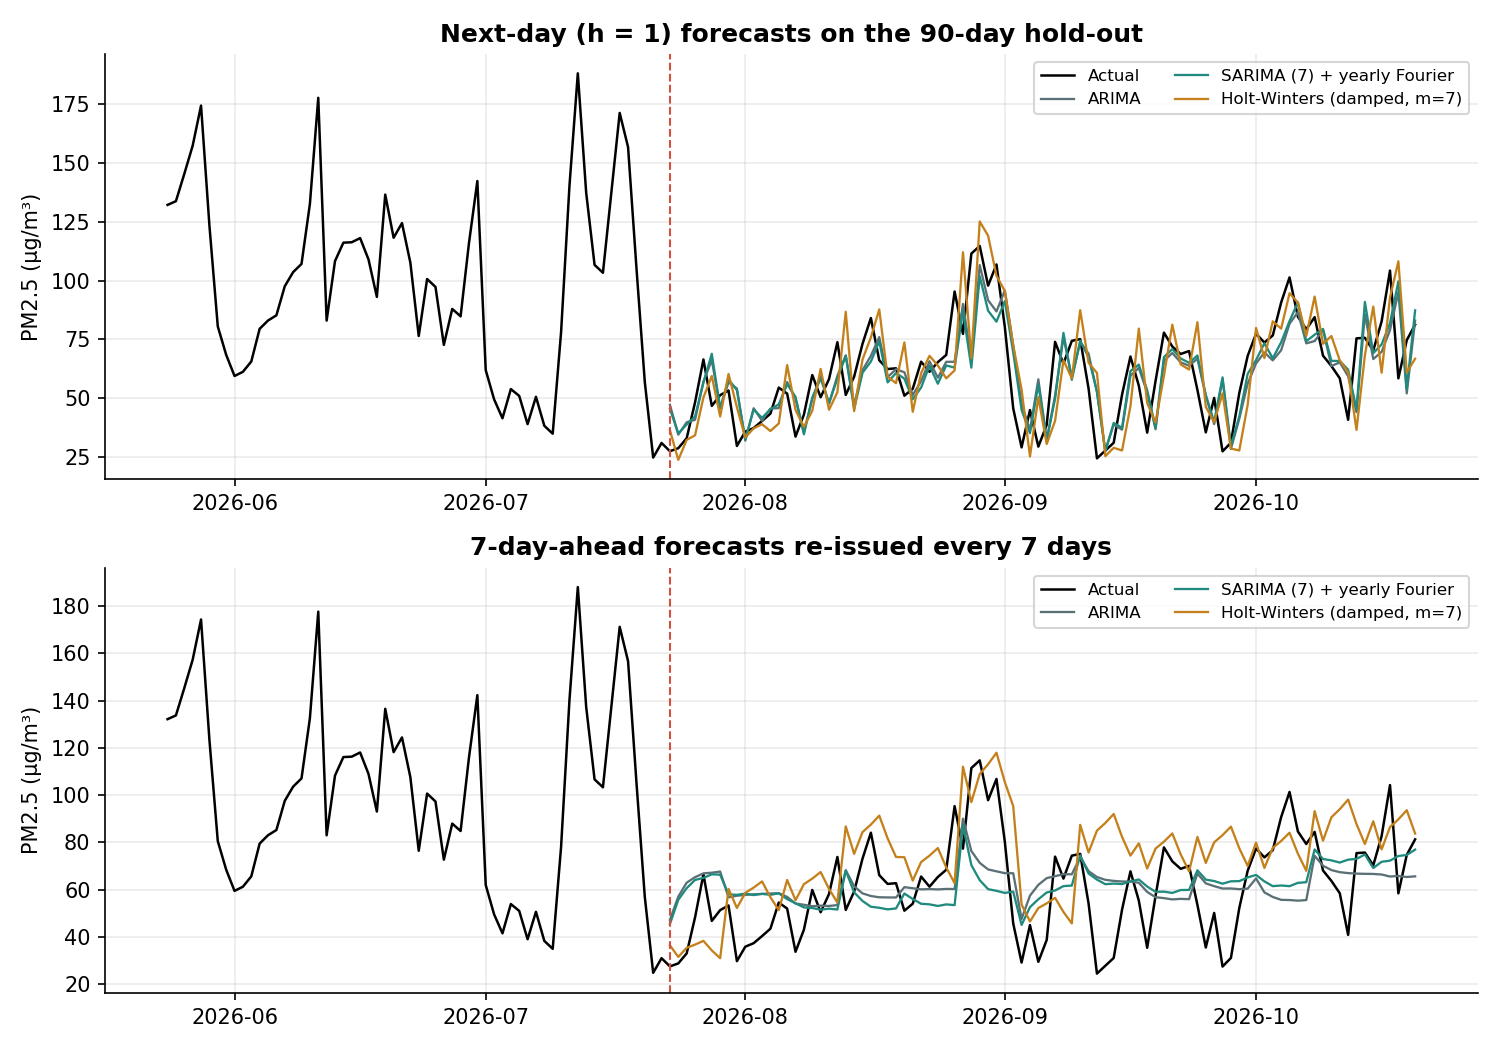

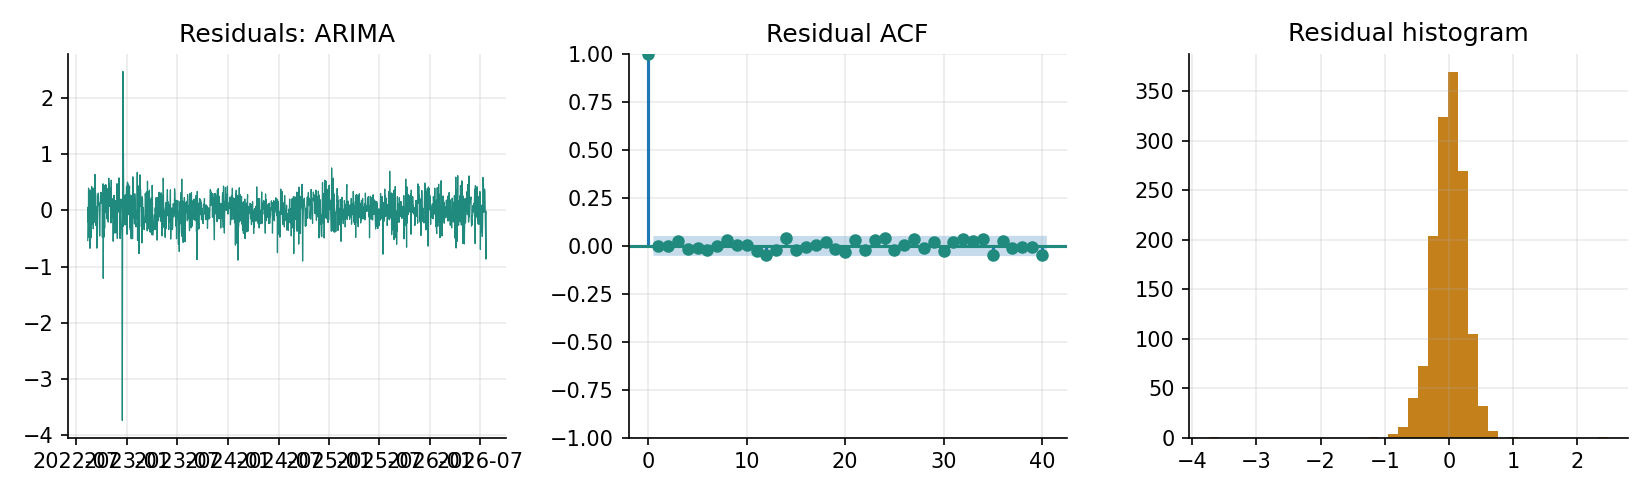

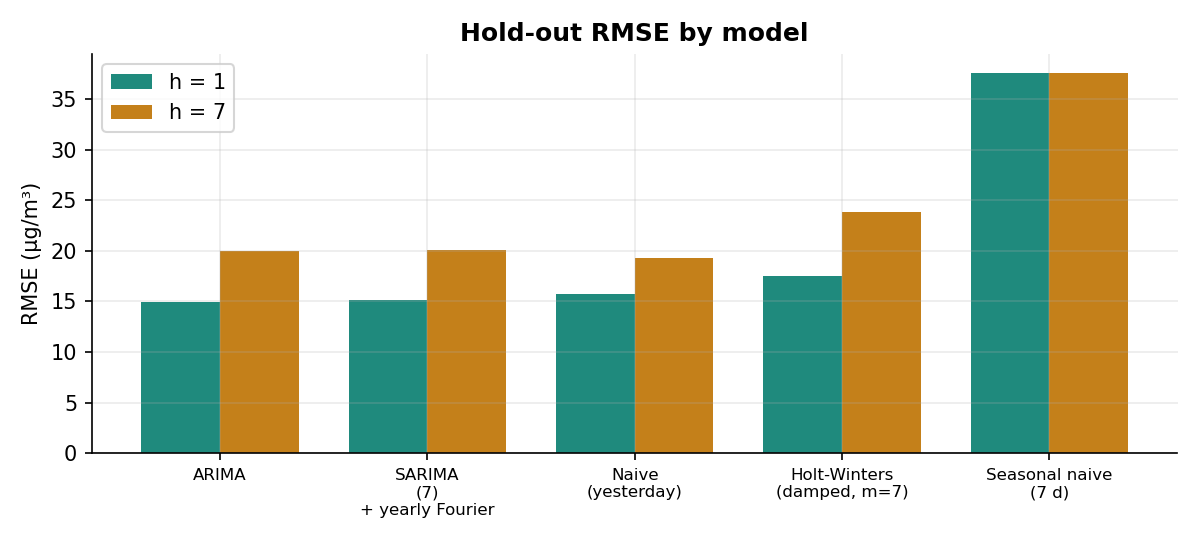

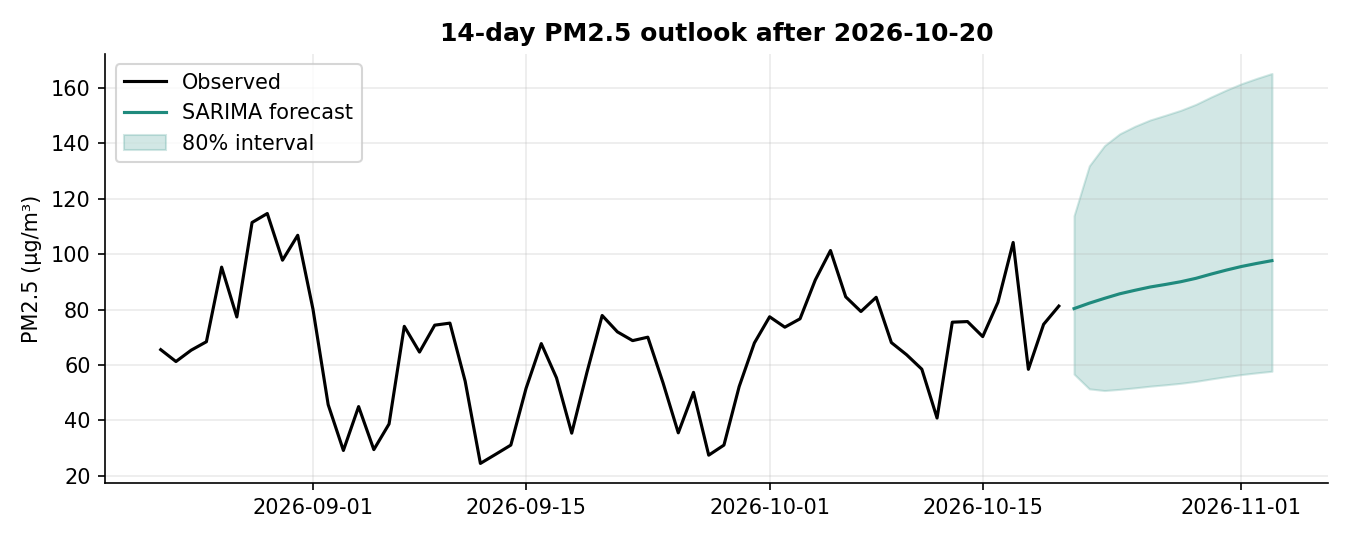

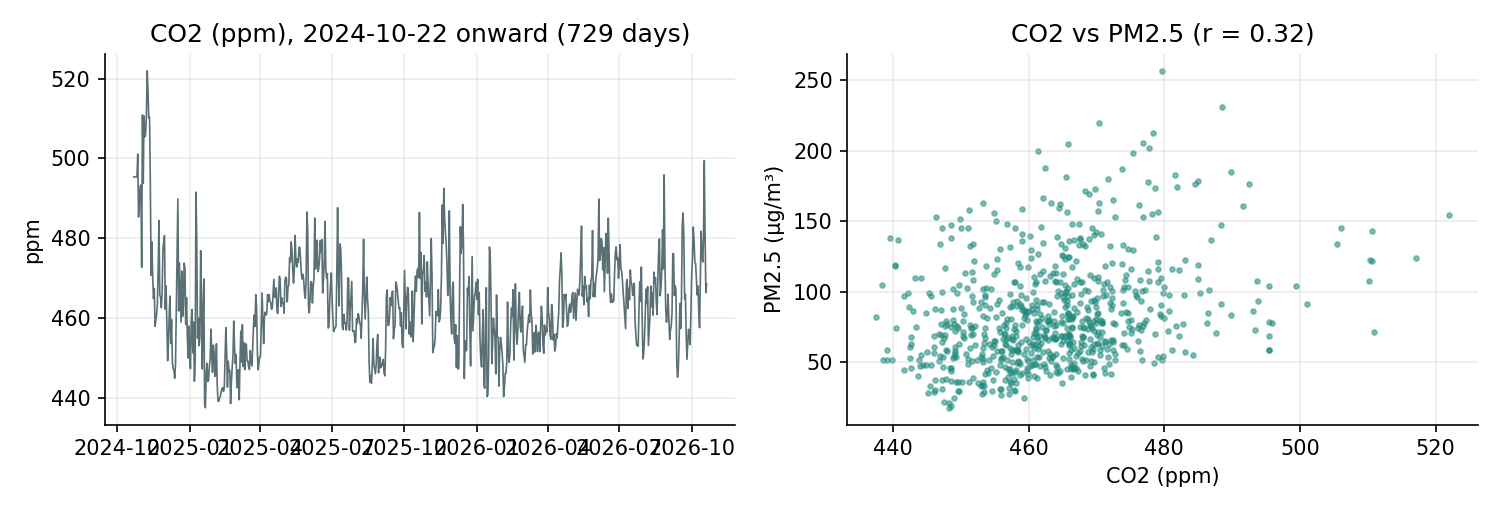

In [6]:
from IPython.display import Image, display
import glob
print(tab.to_string())
for f in sorted(glob.glob(os.path.join(FIG, '*.png'))): display(Image(f, width=800))